# ¿Por qué los bins por encima de N/2 son frecuencias negativas?

En la diapositiva *"Frequency bins are a fixed grid"* (Topic 2) la rejilla con $N=16$ y $f_s=16$ kHz llega hasta 15 kHz. Pero con $f_s = 16$ kHz solo podemos representar sin ambigüedad frecuencias hasta $f_s/2 = 8$ kHz (Nyquist). Este notebook muestra, con gráficas, que los bins $k > N/2$ son en realidad **frecuencias negativas**:

$$k \;\equiv\; k - N \qquad\Rightarrow\qquad f_k = \frac{k}{N}f_s \;\equiv\; \frac{k-N}{N}f_s$$

La razón es que, **en los instantes de muestreo**, una exponencial compleja de bin $k$ es idéntica a la de bin $k-N$:

$$e^{j2\pi (k-N) n/N} = e^{j2\pi k n/N}\,\underbrace{e^{-j2\pi n}}_{=1} = e^{j2\pi k n/N}$$

Partes:
1. Las muestras no distinguen $k$ de $k-N$
2. El fasor: girar 225° hacia un lado = girar 135° hacia el otro
3. Caso real: un coseno de 10 kHz es indistinguible de uno de 6 kHz
4. El espectro de un coseno real: pico en $+k$ y en $N-k \equiv -k$
5. `fftshift`: reordenar el eje para verlo con frecuencias negativas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 16          # tamaño de la DFT
fs = 16000      # frecuencia de muestreo (Hz)
n = np.arange(N)

## 1. Las muestras no distinguen $k$ de $k-N$

Comparamos la exponencial compleja del bin $k=10$ (10 kHz) con la del bin $k-N=-6$ (−6 kHz). Dibujamos la parte real y la imaginaria como curvas continuas y marcamos las muestras enteras $n$.

Las dos curvas continuas son distintas, pero **pasan exactamente por los mismos puntos** en cada $n$ entero. La DFT solo ve esos puntos.

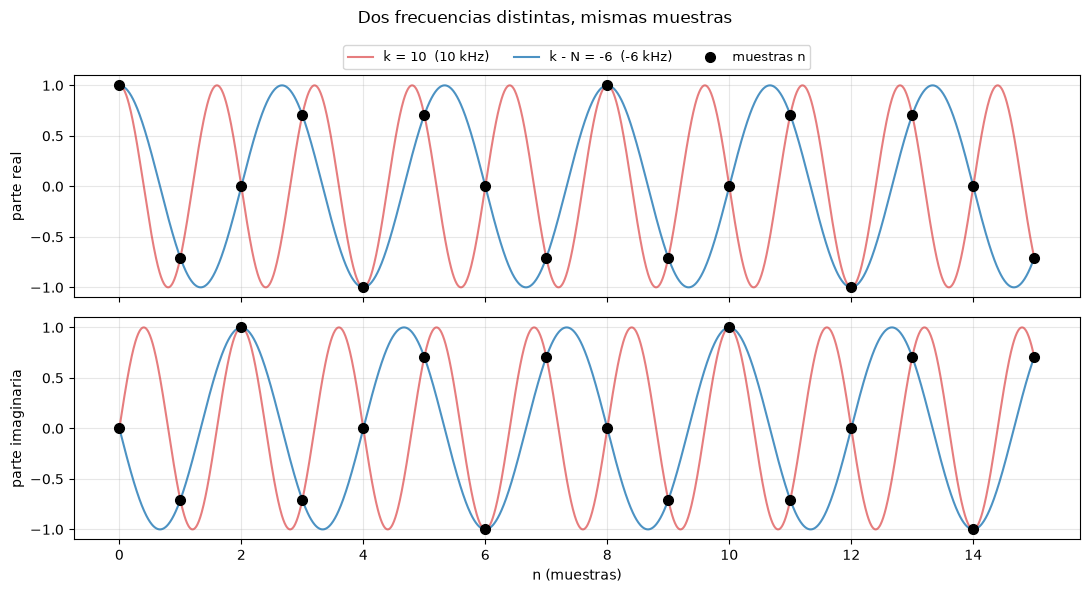

¿Muestras idénticas? True


In [2]:
k = 10
t = np.linspace(0, N - 1, 2000)            # "tiempo continuo" (en muestras)

s_pos = np.exp(1j * 2 * np.pi * k * t / N)         # bin k = 10
s_neg = np.exp(1j * 2 * np.pi * (k - N) * t / N)   # bin k - N = -6
s_n = np.exp(1j * 2 * np.pi * k * n / N)           # muestras (idénticas para ambos)

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, part, name in zip(axs, [np.real, np.imag], ['parte real', 'parte imaginaria']):
    ax.plot(t, part(s_pos), color='tab:red', alpha=0.6, label=f'k = {k}  ({k*fs/N/1000:.0f} kHz)')
    ax.plot(t, part(s_neg), color='tab:blue', alpha=0.8, label=f'k - N = {k-N}  ({(k-N)*fs/N/1000:.0f} kHz)')
    ax.plot(n, part(s_n), 'ko', ms=7, label='muestras n')
    ax.set_ylabel(name)
    ax.grid(alpha=0.3)
axs[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=9)
axs[1].set_xlabel('n (muestras)')
fig.suptitle('Dos frecuencias distintas, mismas muestras')
plt.tight_layout()
plt.show()

print('¿Muestras idénticas?', np.allclose(np.exp(1j*2*np.pi*k*n/N), np.exp(1j*2*np.pi*(k-N)*n/N)))

## 2. El fasor: girar 225° hacia un lado = girar 135° hacia el otro

La exponencial $e^{j\omega_k n}$ es un punto que gira por la circunferencia unidad. Avanza un ángulo $\omega_k = 2\pi k/N$ en cada muestra.

- Con $k=10$: $\omega = 2\pi\cdot 10/16 = 225°$ por muestra (antihorario).
- Con $k=-6$: $\omega = -2\pi\cdot 6/16 = -135°$ por muestra (horario).

Como $225° - 360° = -135°$, **las dos rotaciones caen en los mismos puntos**. Viendo solo una foto por muestra no hay forma de saber si el fasor dio "mucho hacia la izquierda" o "poco hacia la derecha". Es el efecto de la **rueda que parece girar al revés** en las películas: la cámara muestrea la rueda.

La interpretación natural es el giro más corto, $|\omega| \le \pi$, es decir $|f| \le f_s/2$. Por eso los bins $k > N/2$ se leen como frecuencias negativas.

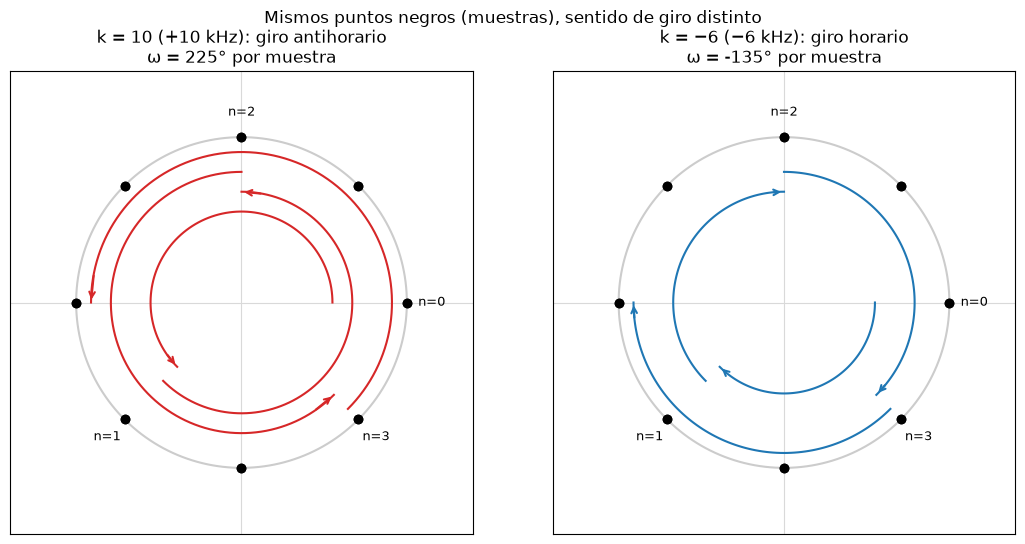

In [3]:
def draw_phasor(ax, k, title, color):
    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), color='0.8')
    ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
    w = 2 * np.pi * k / N
    # primeras 4 muestras y el giro (arco) entre ellas
    for m in range(4):
        a0, a1 = w * m, w * (m + 1)
        arc = np.linspace(a0, a1, 100)
        r = 0.55 + 0.12 * m
        ax.plot(r * np.cos(arc), r * np.sin(arc), color=color, lw=1.5)
        ax.annotate('', xy=(r*np.cos(arc[-1]), r*np.sin(arc[-1])),
                    xytext=(r*np.cos(arc[-6]), r*np.sin(arc[-6])),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.5))
    z = np.exp(1j * w * n)
    ax.plot(z.real, z.imag, 'ko', ms=6)
    for m in range(4):
        ax.text(1.15 * np.cos(w * m), 1.15 * np.sin(w * m), f'n={m}', ha='center', va='center', fontsize=9)
    ax.set_title(f'{title}\nω = {np.degrees(w):.0f}° por muestra')
    ax.set_aspect('equal'); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
    ax.set_xticks([]); ax.set_yticks([])

fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
draw_phasor(axs[0], 10, 'k = 10 (+10 kHz): giro antihorario', 'tab:red')
draw_phasor(axs[1], -6, 'k = −6 (−6 kHz): giro horario', 'tab:blue')
fig.suptitle('Mismos puntos negros (muestras), sentido de giro distinto')
plt.tight_layout()
plt.show()

## 3. Caso real: un coseno de 10 kHz es indistinguible de uno de 6 kHz

Un coseno real es la suma de dos fasores que giran en sentidos opuestos:

$$\cos(\omega n) = \tfrac{1}{2}e^{j\omega n} + \tfrac{1}{2}e^{-j\omega n}$$

Si muestreamos un coseno de **10 kHz** a $f_s = 16$ kHz, sus muestras son idénticas a las de un coseno de $16 - 10 = $ **6 kHz**. Esto es el **aliasing**. Físicamente, si un micrófono capta un tono de 10 kHz y lo muestreamos a 16 kHz sin filtro antialiasing, lo oiremos a 6 kHz.

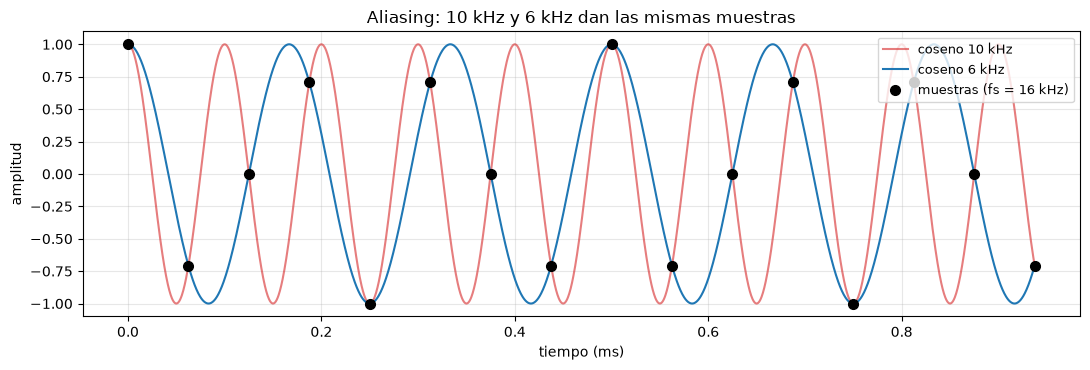

In [4]:
f_hi, f_lo = 10000, fs - 10000          # 10 kHz y su alias de 6 kHz
t_s = np.linspace(0, N - 1, 2000) / fs    # tiempo continuo (s)
n_s = n / fs                              # instantes de muestreo (s)

plt.figure(figsize=(11, 3.8))
plt.plot(t_s * 1000, np.cos(2 * np.pi * f_hi * t_s), color='tab:red', alpha=0.6, label='coseno 10 kHz')
plt.plot(t_s * 1000, np.cos(2 * np.pi * f_lo * t_s), color='tab:blue', label='coseno 6 kHz')
plt.plot(n_s * 1000, np.cos(2 * np.pi * f_hi * n_s), 'ko', ms=7, label='muestras (fs = 16 kHz)')
plt.xlabel('tiempo (ms)'); plt.ylabel('amplitud')
plt.title('Aliasing: 10 kHz y 6 kHz dan las mismas muestras')
plt.legend(loc='upper right', fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. El espectro de un coseno real: pico en $+k$ y en $N-k \equiv -k$

Tomamos un coseno exactamente en el bin $k_0 = 3$ (3 kHz) y calculamos su DFT. Aparecen **dos** picos, en $k=3$ y en $k=13$.

El de $k=13$ no es un tono de 13 kHz (sería imposible con $f_s=16$ kHz). Es la mitad $\tfrac{1}{2}e^{-j\omega_0 n}$ del coseno, la de **frecuencia negativa −3 kHz**, que aparece en el bin $13 = 16 - 3$.

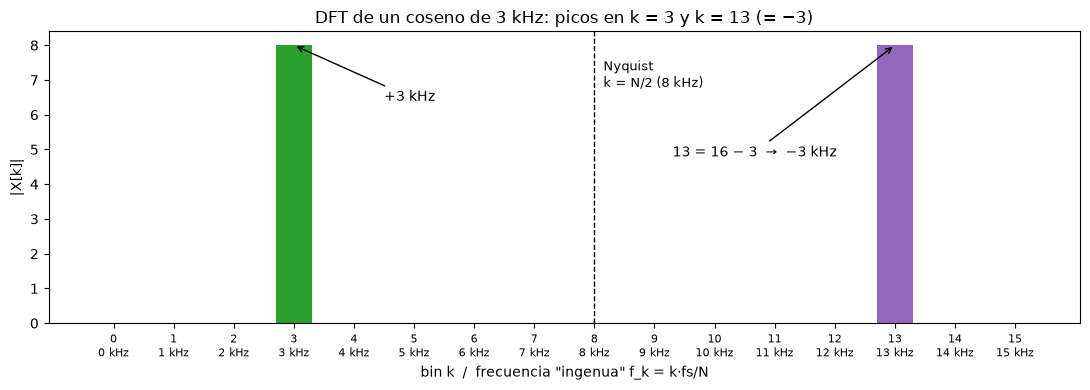

In [5]:
k0 = 3
x = np.cos(2 * np.pi * k0 * n / N)
X = np.fft.fft(x)

f_bins = n * fs / N / 1000                 # "frecuencia" ingenua de cada bin (kHz)

fig, ax = plt.subplots(figsize=(11, 4))
colors = ['tab:green' if k <= N // 2 else 'tab:purple' for k in n]
ax.bar(n, np.abs(X), color=colors, width=0.6)
ax.axvline(N / 2, color='k', ls='--', lw=1)
ax.text(N / 2 + 0.15, N / 2 * 0.95, 'Nyquist\nk = N/2 (8 kHz)', fontsize=9, va='top')
ax.set_xticks(n)
ax.set_xticklabels([f'{k}\n{f:.0f} kHz' for k, f in zip(n, f_bins)], fontsize=8)
ax.set_xlabel('bin k  /  frecuencia "ingenua" f_k = k·fs/N')
ax.set_ylabel('|X[k]|')
ax.set_title('DFT de un coseno de 3 kHz: picos en k = 3 y k = 13 (= −3)')
ax.annotate('+3 kHz', xy=(3, N / 2), xytext=(4.5, N / 2 * 0.8),
            arrowprops=dict(arrowstyle='->'), fontsize=10)
ax.annotate('13 = 16 − 3  →  −3 kHz', xy=(13, N / 2), xytext=(9.3, N / 2 * 0.6),
            arrowprops=dict(arrowstyle='->'), fontsize=10)
plt.tight_layout(); plt.show()

## 5. `fftshift`: reordenar el eje para verlo con frecuencias negativas

Como el bin $k$ y el bin $k-N$ son el mismo, podemos mover la segunda mitad de la DFT a la izquierda del cero. `np.fft.fftshift` hace exactamente eso, y `np.fft.fftfreq` da la frecuencia física de cada bin (ya con signo).

El resultado es un espectro **simétrico** alrededor de 0 Hz: $|X[-k]| = |X[k]|$, como corresponde a una señal real. Toda la información física está entre $0$ y $f_s/2$, por eso en sms-tools solo se dibuja la mitad positiva del espectro.

bin k      : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
f (kHz)    : [ 0  1  2  3  4  5  6  7 -8 -7 -6 -5 -4 -3 -2 -1]


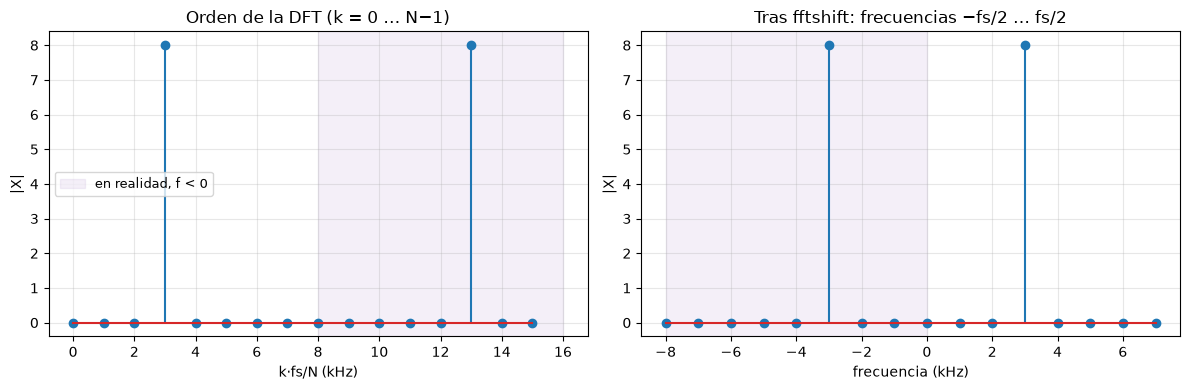

In [6]:
freqs = np.fft.fftfreq(N, d=1 / fs) / 1000      # kHz, ya con signo
print('bin k      :', n)
print('f (kHz)    :', freqs.astype(int))

Xs = np.fft.fftshift(X)
fs_shift = np.fft.fftshift(freqs)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].stem(f_bins, np.abs(X))
axs[0].set_title('Orden de la DFT (k = 0 … N−1)')
axs[0].set_xlabel('k·fs/N (kHz)')
axs[0].axvspan(fs / 2 / 1000, fs / 1000, color='tab:purple', alpha=0.1, label='en realidad, f < 0')
axs[0].legend(fontsize=9)

axs[1].stem(fs_shift, np.abs(Xs))
axs[1].set_title('Tras fftshift: frecuencias −fs/2 … fs/2')
axs[1].set_xlabel('frecuencia (kHz)')
axs[1].axvspan(-fs / 2 / 1000, 0, color='tab:purple', alpha=0.1)
for ax in axs:
    ax.set_ylabel('|X|'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Resumen

- En los instantes de muestreo, $e^{j2\pi kn/N}$ y $e^{j2\pi(k-N)n/N}$ son **idénticas**, así que el bin $k$ y el bin $k-N$ representan lo mismo.
- La lectura física es la del giro más corto del fasor, $|f| \le f_s/2$. Por eso los bins $N/2 < k < N$ corresponden a **frecuencias negativas** $f = (k-N)\,f_s/N$.
- Un coseno real contiene un fasor de $+f$ y otro de $-f$, así que su DFT tiene dos picos simétricos: en $k_0$ y en $N-k_0$.
- Una sinusoide física por encima de $f_s/2$ no "aparece en un bin alto". Se **pliega** (aliasing) a una frecuencia por debajo de Nyquist.

En la rejilla de la diapositiva ($N=16$, $f_s=16$ kHz), los bins 9–15 no son 9–15 kHz. Son **−7 … −1 kHz**.